# C3-WM's link, built from blocks

> C3-WM's communication model as a pipeline of comm-core blocks, its gain predictor replaced by the geometry + history quantile model, on ray-traced FindGoal layouts.

C3-WM (Elbakary, Weeraddana and Bennis) lets agents with local world models exchange discrete tokens over a wireless
link, and sets each transmission's power from a predicted channel gain. Its communication model (Sections III-B and
IV-B) is a chain of steps, and each one is a comm-core block (see `block`). Built as a `PipelineBackend`, each step can be
replaced on its own:

| C3-WM | | block |
|---|---|---|
| the channel `h_t`: ray-traced (Sionna RT) at the agents' cells, constant during a message | eq. 4 | `RayTracedFading` |
| the power, `ρ̂ = Γσ²/ŷ`, from a predicted gain `ŷ` | eqs. 24–26 | a `PowerControl` |
| the scheduling, `δ = 1(ρ̂ ≤ ρ_max)` | eq. 27 | `Schedule` (below) |
| 49 tokens of 8 bits, BPSK, `y = h √ρ x + n` at the SNR `|h|² ρ / σ²`, coherent ML detection | eqs. 3–6 | `BitLevelLink(IndexCodec(256), BPSK())` |
| the received tokens, or the out-of-vocabulary embedding | eq. 13 | `Tokens` (below) |
| the communication cost | Fig. 8b | `Airtime`, and the network's metrics |

Two changes, the point of the example:

* **The gain predictor.** C3-WM's `Ψ` is linear in `|h|²` over the link's last 4 gains (eq. 24). It is replaced by the
  *geometry + history quantile* model of [power control on new layouts](07_power_across_layouts.ipynb): gradient-boosted
  trees on the past gains, the agents' moves and the layout's walls, predicting the gain's 5% quantile. Swapping it
  is swapping one block.
* **A margin, and the scheduling rule.** Both predictors are also given a margin `κ`, chosen on held-out layouts, and
  run with C3-WM's `δ` and with best effort (never withhold, send at most `ρ_max`). The rule is its own block.

Nothing new is ray-traced: the 40 FindGoal layouts of example 07 (`data/findgoal_layouts.npz`) are used. Two agents
move at random. C3-WM's TDMA gives every directed link its own sub-slot, so transmissions never overlap: there is
no `Interference` block. Adding one would model a shared slot. Each agent sends its 49 tokens to the other at
every step; random tokens stand in for MsgNet's. `Γ = 10 dB`, `σ² = −94 dBm` and `ρ_max = 20 dBm`, as in example 07.

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

from comm_core import *

## The layouts and the agents

As in example 07: each layout holds the ray-traced gain between every pair of free cells and the walls. Agents turn,
step forward or wait at random, like a random policy in FindGoal.

In [ ]:
data = np.load('data/findgoal_layouts.npz')
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]

class Layout:
    "One ray-traced layout: the gain between any two free cells, and the walls between them."
    def __init__(self, k):
        self.seed = int(data['seeds'][k])
        self.cells = [tuple(int(v) for v in c) for c in data['cells'][k]]
        self.idx = {c: i for i, c in enumerate(self.cells)}
        self.G = 10 ** (data['gain_db'][k].astype(float) / 10)               # G[rx, tx]
        self.walls = data['walls'][k]

    def geometry(self, a, b):
        "Distance (cells) and the number of wall cells the straight line between the two cell centres crosses."
        n = max(int(abs(a[0] - b[0]) + abs(a[1] - b[1])) * 4, 1)
        xs, ys = np.linspace(a[0], b[0], n + 1), np.linspace(a[1], b[1], n + 1)
        crossed = {(int(round(x)), int(round(y))) for x, y in zip(xs, ys)} - {a, b}
        return math.hypot(a[0] - b[0], a[1] - b[1]), int(sum(self.walls[c] for c in crossed))

layouts = {int(s): Layout(k) for k, s in enumerate(data['seeds'])}
FIT, CALIBRATION, TEST = range(0, 24), range(24, 30), range(100, 110)
STEPS, HISTORY, ROLLOUTS = 60, 4, 5
AGENTS = ['agent_0', 'agent_1']

def walk(lay, seed):
    "One episode: per step, both agents' cells and headings."
    rng = np.random.default_rng(seed)
    free = set(lay.cells)
    pos = [lay.cells[k] for k in rng.choice(len(lay.cells), 2, replace=False)]
    head = [int(h) for h in rng.integers(4, size=2)]
    out = []
    for _ in range(STEPS):
        out.append((tuple(pos), tuple(head)))
        for a in rng.permutation(2):
            action = rng.integers(4)                                     # left, right, forward, nothing
            if action < 2:
                head[a] = (head[a] + (1 if action else -1)) % 4
            elif action == 2:
                ahead = (pos[a][0] + DIRS[head[a]][0], pos[a][1] + DIRS[head[a]][1])
                if ahead in free and ahead != pos[1 - a]:
                    pos[a] = ahead
    return out

## The channel

As in C3-WM, the channel of a link is the ray-traced coefficient between the two agents' cells (Section V): it is
constant during a message (quasi-static, eq. 4) and changes when an agent moves. `RayTracedFading` looks it up in
the layout's table, at the cells it is told (`set_positions`).

## Collecting C3-WM's channel data with the blocks

C3-WM trains its predictor on `D_channel` (eq. 22): each directed link's last gains and its current one. Here they
come from the same block the network will use, called outside any network on a step's transmissions and links, once
per step of each episode. Training and deployment see the same channel by construction.

In [ ]:
db = lambda g: 10 * np.log10(np.maximum(g, 1e-30))
LINKS = [(Transmission(Message(a, b, None), a, b, 0.0), Link(a, b)) for a, b in (AGENTS, AGENTS[::-1])]

def channel_data(seeds):
    "Per directed link and step (after the first HISTORY): what the transmitter knows, and the true gain."
    out = []
    for seed in seeds:
        lay = layouts[seed]
        for k in range(ROLLOUTS):
            episode = walk(lay, 1000 * seed + k)
            table = RayTracedFading(np.sqrt(lay.G).astype(complex), lay.cells)
            gains = []
            for t, (cells, _) in enumerate(episode):
                table.set_positions(dict(zip(AGENTS, cells)))
                gains.append(np.abs(table(*zip(*LINKS))[:, 0]) ** 2)     # the block alone: h of both links
            gains = np.array(gains)                                      # (steps, 2): agent_0 -> agent_1, back
            for j, i in ((0, 1), (1, 0)):
                g = gains[:, j]
                for t in range(HISTORY, len(episode)):
                    (now, _), (before, heads), (earlier, _) = episode[t], episode[t - 1], episode[t - 2]
                    ahead = (before[i][0] + DIRS[heads[i]][0], before[i][1] + DIRS[heads[i]][1])
                    possible = [c for c in (before[i], ahead) if c in lay.idx and c != now[j]] or [before[i]]
                    out.append(dict(lay=lay, tx=now[j], rx=now[i], possible=possible, past=g[t - HISTORY:t][::-1].copy(),
                                    moved=[float(now[j] != before[j]), float(before[i] != earlier[i])], gain=g[t]))
    return out

fit, cal = channel_data(FIT), channel_data(CALIBRATION)
print(f'{len(fit)} transmissions to fit on (layouts 0-23), {len(cal)} to calibrate on (24-29)')

13440 transmissions to fit on (layouts 0-23), 3360 to calibrate on (24-29)


Both predictors are fit on the same data. C3-WM's `Ψ` by least squares on `|h|²` (eq. 24, `fit_gain_predictor`); the
quantile model on the link's past gains in dB, the agents' moves, and the distance and walls to the receiver's cell.
At run time, the receiver's cell is known only as of its last report, so the quantile model predicts for each cell
the receiver can have reached since, and takes the lowest (example 07).

In [ ]:
def features(r, cell):
    distance, walls = r['lay'].geometry(r['tx'], cell)
    return [math.log10(max(distance, 0.5)), distance, walls] + list(db(r['past'])) + r['moved']

psi = fit_gain_predictor([np.r_[r['past'][::-1], r['gain']] for r in fit], history=HISTORY)
model = HistGradientBoostingRegressor(loss='quantile', quantile=0.05, max_iter=400, learning_rate=0.05, early_stopping=False,
                                      random_state=0).fit(np.array([features(r, r['rx']) for r in fit]), db(np.array([r['gain'] for r in fit])))

def quantile_estimate(rs):
    "The quantile model's gain, the lowest over each transmission's possible cells."
    pairs = [(k, c) for k, r in enumerate(rs) for c in r['possible']]
    out = np.full(len(rs), np.inf)
    np.minimum.at(out, [k for k, _ in pairs], model.predict(np.array([features(rs[k], c) for k, c in pairs])))
    return 10 ** (out / 10)

estimates = {"C3-WM's Ψ": lambda rs: np.array([max(psi(r['past']), 0.0) for r in rs]),    # eq. 25
             'geometry + history quantile': quantile_estimate}

**The margin.** A prediction misses the true gain by its error, so the power aims `κ` dB above `Γ`:
`ρ̂ = 10^(κ/10) Γσ²/ŷ`. Each predictor's `κ` is the smallest that brings 99% of the *servable* transmissions to `Γ`
on the calibration layouts, sending at most `ρ_max`. A transmission is servable if perfect CSI could deliver it:
its gain is at least `Γσ²/ρ_max`. C3-WM itself uses no margin (`κ = 0`).

In [ ]:
SNR_TARGET_DB, NOISE_DBM, MAX_POWER_DBM = 10.0, -94.0, 20.0
NOISE_W, MAX_POWER_W = 10 ** ((NOISE_DBM - 30) / 10), 10 ** ((MAX_POWER_DBM - 30) / 10)
GAMMA = 10 ** (SNR_TARGET_DB / 10)
G_MIN = GAMMA * NOISE_W / MAX_POWER_W                                  # the weakest servable gain
MARGINS = np.arange(0, 40.01, 0.25)

def calibrate(estimate, target=0.99):
    "(κ, share reaching Γ): the smallest κ reaching `target` on the calibration layouts, else the most reliable."
    g, ghat = np.array([r['gain'] for r in cal]), estimate(cal)
    servable, best = g >= G_MIN, None
    for margin in MARGINS:
        power = np.minimum(10 ** ((SNR_TARGET_DB + margin) / 10) * NOISE_W / np.maximum(ghat, 1e-300), MAX_POWER_W)
        share = (power * g / NOISE_W >= GAMMA * (1 - 1e-9))[servable].mean()
        if share >= target:
            return margin, share
        if best is None or share > best[1]:
            best = (margin, share)
    return best

margins = {name: calibrate(e) for name, e in estimates.items()}
for name, (margin, share) in margins.items():
    print(f'{name:28s} κ = {margin:5.2f} dB: {100 * share:.1f}% of the servable calibration transmissions reach Γ')

C3-WM's Ψ                    κ = 40.00 dB: 97.5% of the servable calibration transmissions reach Γ
geometry + history quantile  κ =  7.75 dB: 99.0% of the servable calibration transmissions reach Γ


## The power and the scheduling: two blocks

C3-WM's eq. 26 (the power) and eq. 27 (whether to send) are separate steps, so they are separate blocks:

* **The power** is a `PowerControl`. C3-WM's `Ψ` is comm-core's `PredictedChannelInversion`, which keeps each link's
  past gains and uses a fallback power for the first `L` steps, as C3-WM does. The quantile model's is
  `LearnedChannelInversion`, as in example 07. It needs the receiver's last reported cell and heading (`update`
  notes where the agents are at every round), and the layout's walls.
* **The scheduling** is `Schedule`. It sends only if the power asked for is within `10^(τ/10) ρ_max`, at no more
  than `ρ_max`. `τ = 0` is C3-WM's `δ`; `τ = ∞` never withholds (best effort). It takes `power` and `active` and
  gives them back narrowed, so it goes right after any power control.

In [ ]:
class LearnedChannelInversion(PowerControl):
    "Eq. 26 with the gain from `model` (features -> dB), the lowest over the receiver's possible cells."

    def __init__(self, model, layout, table, headings, target_snr_db, margin_db, fallback_power):
        self.model, self.layout, self.table, self.headings = model, layout, table, headings
        self.target_snr_db, self.margin_db, self.fallback_power = target_snr_db, margin_db, fallback_power
        self.reset()

    def children(self):
        return []

    def reset(self, seed=None):
        self._past, self._rounds = {}, []

    def update(self, time):
        "A new round: where the agents are now, and their headings; the earlier rounds are what they reported."
        self._rounds = (self._rounds + [(dict(self.table.node_positions), dict(self.headings()))])[-3:]

    def allocate(self, gain, noise_power, link=None, message=None):
        past = self._past.setdefault((link.sender, link.receiver), [])
        if len(past) < HISTORY or len(self._rounds) < 3:
            power = self.fallback_power                                  # not enough history yet
        else:
            (earlier, _), (before, heads), (now, _) = self._rounds
            tx, rx = now[link.sender], before[link.receiver]
            d = DIRS[heads[link.receiver]]
            possible = [c for c in (rx, (rx[0] + d[0], rx[1] + d[1])) if c in self.layout.idx and c != tx] or [rx]
            r = dict(lay=self.layout, tx=tx, past=np.array(past[-HISTORY:][::-1]),
                     moved=[float(tx != before[link.sender]), float(rx != earlier[link.receiver])])
            predicted = 10 ** (min(self.model.predict(np.array([features(r, c) for c in possible]))) / 10)
            power = 10 ** ((self.target_snr_db + self.margin_db) / 10) * noise_power / predicted
        past.append(float(gain))                                        # fed back after the transmission
        return power, True                                              # whether to send: `Schedule`'s


class Schedule(Block):
    "Eq. 27: send only if the power asked for is within the budget, `10^(τ/10) ρ_max`, at no more than `ρ_max`."
    outputs = ('power', 'active')

    def __init__(self, max_power, tau_db=0.0):
        self.max_power, self.tau_db = max_power, tau_db

    def call(self, power, active):
        return np.minimum(power, self.max_power), np.asarray(active) & (power <= self.max_power * 10 ** (self.tau_db / 10))

## What the receiver gets

C3-WM has no CRC: the receiver maps whatever bits it detects back to tokens (eq. 8), errors included. When nothing
arrives, its world model gets the out-of-vocabulary embedding `e_OOV` instead (as for future steps, eq. 13). `Tokens`
is that last step: the tokens received, or `OOV` in each place when nothing arrived. It also counts the wrong
tokens into the results' metadata (`info`).

In [ ]:
OOV = -1                                                               # the out-of-vocabulary token

class Tokens(Block):
    "The tokens the receiver's world model gets: the ones detected, or OOV in each place when nothing arrived."
    outputs = ('payload', 'info')

    def call(self, transmission, success, payload, info):
        tokens, extra = [], []
        for t, ok, p, i in zip(transmission, success, payload, info):
            sent = np.asarray(t.message.payload)
            got = np.asarray(p) if ok else np.full(sent.shape, OOV)
            tokens.append(got)
            extra.append({**i, 'wrong_tokens': int((got != sent).sum()) if ok else None})
        return tokens, extra

## The link, as a pipeline

The whole link is a list of blocks, given to a `PipelineBackend`. The pipeline checks the wiring when it is built:
each block's inputs must be the step's, `noise_power`, or an earlier block's outputs.

In [ ]:
def link(lay, power_control, tau_db, crc=False):
    "C3-WM's link in one layout, with a power control, a scheduling threshold, and optionally a CRC."
    table = RayTracedFading(np.sqrt(lay.G).astype(complex), lay.cells)
    return [table, power_control(lay, table), Schedule(MAX_POWER_W, tau_db),
            BitLevelLink(IndexCodec(256), BPSK(), drop_corrupted=crc), Tokens(), Airtime()]

backend = PipelineBackend(link(layouts[100], lambda lay, table: ChannelInversion(SNR_TARGET_DB), 0.0), noise_power=NOISE_W)
print(' → '.join(type(b).__name__ for b in backend.pipeline))

RayTracedFading → ChannelInversion → Schedule → BitLevelLink → Tokens → Airtime


The power controls compared, each one block of the list:

In [ ]:
headings = {}                                                          # the agents' headings, set at every step
CONTROLS = {                                                           # name: (power control, τ[, CRC])
    'perfect CSI (eq. 21)':
        (lambda lay, table: ChannelInversion(SNR_TARGET_DB), 0.0),
    "C3-WM as written: Ψ, κ = 0, δ":
        (lambda lay, table: PredictedChannelInversion(psi, HISTORY, SNR_TARGET_DB, fallback_power=MAX_POWER_W), 0.0),
    "C3-WM's Ψ, κ, best effort":
        (lambda lay, table: PredictedChannelInversion(psi, HISTORY, SNR_TARGET_DB, fallback_power=MAX_POWER_W,
                                                      margin_db=margins["C3-WM's Ψ"][0]), math.inf),
    'geometry + history, κ, δ':
        (lambda lay, table: LearnedChannelInversion(model, lay, table, lambda: headings, SNR_TARGET_DB,
                                                    margins['geometry + history quantile'][0], MAX_POWER_W), 0.0),
    'geometry + history, κ, best effort':
        (lambda lay, table: LearnedChannelInversion(model, lay, table, lambda: headings, SNR_TARGET_DB,
                                                    margins['geometry + history quantile'][0], MAX_POWER_W), math.inf),
    'geometry + history, κ, best effort, CRC':
        (lambda lay, table: LearnedChannelInversion(model, lay, table, lambda: headings, SNR_TARGET_DB,
                                                    margins['geometry + history quantile'][0], MAX_POWER_W), math.inf, True),
}

## Through a network, on unseen layouts

Each power control runs on layouts 100–109, which neither the fit nor the calibration saw: 5 episodes per layout,
60 steps each, every agent sending its 49 tokens to the other at every step. The first `L = 4` steps, while the
predictors have no history, are left out of the results.

In [ ]:
def run(power_control, tau_db, crc=False):
    "The results after the first HISTORY steps, and the communication cost per episode (KB)."
    results, cost = [], []
    for seed in TEST:
        lay = layouts[seed]
        for k in range(ROLLOUTS):
            backend = PipelineBackend(link(lay, power_control, tau_db, crc), noise_power=NOISE_W)
            net = Network([Node(a) for a in AGENTS], FullMeshTopology(AGENTS), IdealProtocol(), backend)
            net.reset(seed=1000 * seed + k)
            tokens = np.random.default_rng(1000 * seed + k)                  # stand-ins for MsgNet's tokens
            for t, (cells, heads) in enumerate(walk(lay, 1000 * seed + k)):
                backend.set_positions(dict(zip(AGENTS, cells)))
                headings.update(zip(AGENTS, heads))
                for a, b in ((0, 1), (1, 0)):
                    net.send(Message(AGENTS[a], AGENTS[b], payload=tokens.integers(256, size=49)))
                results += [r for r in net.step() if t >= HISTORY]
            cost.append(net.metrics.summary().bits_sent / 8 / 1000)
    return results, np.mean(cost)

def summary(results, cost):
    g = np.array([10 ** (r.metadata['channel_gain_db'] / 10) for r in results])
    p = np.array([r.metadata['tx_power'] for r in results])
    servable = g >= G_MIN
    return dict(
        reached=(p * g / NOISE_W >= GAMMA * (1 - 1e-9))[servable].mean(),       # servable ones reaching Γ
        power=p.mean() / np.where(servable, GAMMA * NOISE_W / g, 0).mean(),     # × perfect CSI's
        withheld=np.mean([bool(r.metadata.get('outage')) for r in results]),
        intact=np.mean([r.success and r.metadata['wrong_tokens'] == 0 for r, s in zip(results, servable) if s]),
        wrong=np.mean([r.metadata['wrong_tokens'] / 49 for r in results if r.success] or [0.0]),
        garbled=np.mean([r.success and r.metadata['wrong_tokens'] > 0 for r, s in zip(results, servable) if not s]),
        cost=cost)

out = {name: summary(*run(*control)) for name, control in CONTROLS.items()}
print(f"{'':42s}{'reach Γ':>9s}{'power':>11s}{'withheld':>10s}{'intact':>9s}{'wrong':>8s}{'garbled':>9s}{'cost':>13s}")
for name, s in out.items():
    print(f"{name:42s}{100 * s['reached']:8.1f}%{s['power']:10.3g}×{100 * s['withheld']:9.1f}%{100 * s['intact']:8.1f}%"
          f"{100 * s['wrong']:7.2f}%{100 * s['garbled']:8.1f}%{s['cost']:8.2f} KB/ep")

                                            reach Γ      power  withheld   intact   wrong  garbled         cost
perfect CSI (eq. 21)                         100.0%         1×      6.3%    99.9%   0.00%     0.0%    5.50 KB/ep
C3-WM as written: Ψ, κ = 0, δ                 19.9%   0.00138×      0.0%    39.3%  46.45%   100.0%    5.88 KB/ep
C3-WM's Ψ, κ, best effort                     98.1%      13.7×      0.0%    99.9%   2.81%    82.1%    5.88 KB/ep
geometry + history, κ, δ                      88.1%      2.01×     16.4%    88.5%   0.23%     2.3%    4.98 KB/ep
geometry + history, κ, best effort            99.0%      6.79×      0.0%    99.6%   2.63%    72.4%    5.88 KB/ep
geometry + history, κ, best effort, CRC       99.0%      6.79×      0.0%    99.6%   0.00%     0.0%    5.88 KB/ep


* **reach Γ:** the share of the servable transmissions whose SNR reaches `Γ`.
* **power:** the mean transmit power, relative to perfect CSI's (exactly `Γσ²/g` on each servable transmission,
  nothing on the others).
* **withheld:** the share not sent (`δ = 0`): the receiver gets `e_OOV`.
* **intact:** the share of the servable transmissions arriving with all 49 tokens right.
* **wrong:** the share of wrong tokens in what arrived. The receiver can't tell them from right ones.
* **garbled:** the share of the *unservable* transmissions that arrive with wrong tokens: sent at `ρ_max`
  although no power could reach `Γ`.
* **cost:** the bits sent per episode (C3-WM's Fig. 8b), in KB.

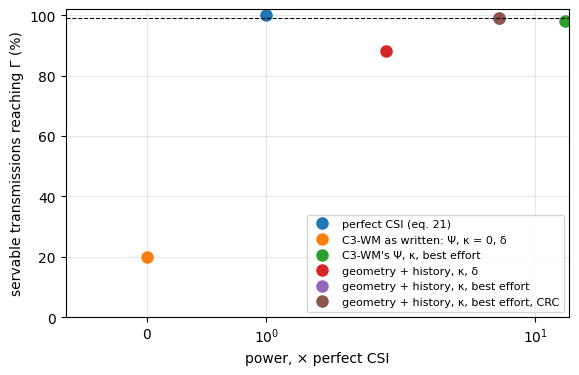

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, s in out.items():
    ax.plot(s['power'], 100 * s['reached'], 'o', ms=8, label=name)
ax.axhline(99, color='k', lw=0.8, ls='--')
ax.set(xscale='symlog', xlabel='power, × perfect CSI', ylabel='servable transmissions reaching Γ (%)', ylim=(0, 102))
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='lower right')
plt.show()

* **C3-WM as written fails here.** `Ψ`, fit by least squares on `|h|²` (eq. 24), is dominated by the strong links. Its
  predictions never go below about −63 dB, while half of the links are weaker than −66 dB and a link is servable down
  to −104 dB. A weak link therefore gets a small fraction of the power it needs (0.14% of perfect CSI's, overall).
  Only 20% of the servable transmissions reach `Γ`, and 46% of the tokens that arrive are wrong. Example 07 found
  the same bias.
* **A margin helps `Ψ`, but not enough.** With 40 dB, the largest tried, it brings 97.5% of the calibration
  transmissions to `Γ` and 98.1% of the unseen ones, never 99%, at 13.7× perfect CSI's power. Its error depends on the
  link's strength, and one margin can't correct all of them.
* **The geometry + history quantile model meets the target, at half the power.** Its 7.75 dB margin, chosen on 6
  layouts, brings 99.0% of the servable transmissions on 10 unseen layouts to `Γ`, at 6.8× perfect CSI's power.
* **C3-WM's `δ` withholds too much once there is a margin.** With the same model and margin,
  `δ = 1(ρ̂ ≤ ρ_max)` withholds 16% of the transmissions, servable ones among them, and only 88% reach `Γ`. It
  is cheaper (2.0× the power, 4.98 instead of 5.88 KB per episode), and what it withholds arrives as `e_OOV`, which
  the world model reads as "no message".
* **Best effort without a CRC feeds wrong tokens to the world model.** Sent at `ρ_max`, 72% of the unservable
  transmissions arrive with wrong tokens, and the receiver can't tell: 2.6% of the tokens it gets are wrong. A CRC
  (`BitLevelLink(drop_corrupted=True)`, one argument) turns them into `e_OOV` instead, with the same reliability:
  99.6% of the servable messages still arrive intact, and no wrong token reaches the world model. The CRC's own bits
  (e.g. 24 per message) are not counted here.

## Changing it further

Each step is one block of the list, so a variant changes one entry:

* **A shared slot instead of TDMA sub-slots:** `Interference(table)` after `Schedule`, so that the other senders'
  power is added to the noise.
* **Coded 5G NR instead of uncoded BPSK:** `SionnaLink` in place of `BitLevelLink` (see `link_level`).
* **Another predictor:** another `PowerControl` before `Schedule`, e.g. `MapChannelInversion` with a ray-traced map
  (a digital twin, if every layout can be ray-traced).
* **Another scheduling rule:** `Schedule(ρ_max, τ)` with `τ` between 0 and ∞. Example 07 tunes it.

The numbers depend on the setting: two agents moving at random in FindGoal's layouts, and random tokens standing in
for MsgNet's.

## Between δ and best effort: the threshold τ

`δ` and best effort are the two ends of one rule: withhold a transmission only when its power would exceed
`10^(τ/10) ρ_max`, and send the others at no more than `ρ_max`. `τ = 0` is C3-WM's `δ`; `τ = ∞` never withholds.
In between, a transmission predicted to need a little more than `ρ_max` is still sent, at `ρ_max`, and one predicted
to need far more is withheld.

The margin and the threshold work together: with a finite `τ`, a larger margin also withholds more. So each `τ`
gets its own margin, the smallest that reaches the target on the calibration layouts. Then each pair is judged on
the unseen layouts, for a 95% and a 99% target.

This sweep is analytic. It applies each `(κ, τ)` to the same predictions the power control makes in the network
(`quantile_estimate` on the unseen layouts' episodes), with the BPSK bit error rate for what arrives garbled. Two of
the pairs are checked through the network below.

In [ ]:
TAUS = (0.0, 2, 4, 6, 8, 10, 12, 15, 20, 30, math.inf)
test = channel_data(TEST)
ghat = {'cal': quantile_estimate(cal), 'test': quantile_estimate(test)}
gain = {'cal': np.array([r['gain'] for r in cal]), 'test': np.array([r['gain'] for r in test])}
ber = np.vectorize(bpsk_bit_error_rate)

def outcome(split, margin, tau):
    "(servable reaching Γ, power × perfect CSI, withheld, unservable arriving garbled) of a (κ, τ) on a split."
    g = gain[split]
    rho = 10 ** ((SNR_TARGET_DB + margin) / 10) * NOISE_W / np.maximum(ghat[split], 1e-300)
    sent = rho <= MAX_POWER_W * 10 ** (tau / 10)
    power = np.where(sent, np.minimum(rho, MAX_POWER_W), 0.0)
    servable, snr = g >= G_MIN, power * g / NOISE_W
    garbled = np.where(sent, 1 - (1 - ber(snr)) ** (49 * 8), 0.0)               # P(some bit wrong)
    return ((snr >= GAMMA * (1 - 1e-9))[servable].mean(), power.mean() / np.where(servable, GAMMA * NOISE_W / g, 0).mean(),
            1 - sent.mean(), garbled[~servable].mean())

def margin_for(target, tau):
    "The smallest κ reaching `target` on the calibration layouts with this τ; else the most reliable."
    shares = [outcome('cal', m, tau)[0] for m in MARGINS]
    met = [m for m, s in zip(MARGINS, shares) if s >= target]
    return (met[0], True) if met else (MARGINS[int(np.argmax(shares))], False)

sweep = {}
for target in (0.95, 0.99):
    for tau in TAUS:
        margin, met = margin_for(target, tau)
        sweep[target, tau] = dict(zip(('reached', 'power', 'withheld', 'garbled'), outcome('test', margin, tau)),
                                  margin=margin, met=met, cal_power=outcome('cal', margin, tau)[1])

label = lambda tau: '∞' if math.isinf(tau) else f'{tau:g}'
for target in (0.95, 0.99):
    print(f'target {100 * target:.0f}%: τ (dB), κ (dB), then on the unseen layouts: reach Γ / power / withheld / garbled '
          f'(✗: target not reached on the calibration layouts)')
    for tau in TAUS:
        s = sweep[target, tau]
        print(f"  τ = {label(tau):>3s}   κ = {s['margin']:5.2f}   {100 * s['reached']:5.1f}%  {s['power']:5.2f}×  "
              f"{100 * s['withheld']:4.1f}%  {100 * s['garbled']:4.1f}%{'' if s['met'] else '  ✗'}")

target 95%: τ (dB), κ (dB), then on the unseen layouts: reach Γ / power / withheld / garbled (✗: target not reached on the calibration layouts)
  τ =   0   κ =  0.50    92.2%   1.28×   9.7%   5.4%  ✗
  τ =   2   κ =  0.75    93.6%   1.62×   8.7%   5.6%  ✗
  τ =   4   κ =  2.50    95.0%   2.16×   8.6%   5.4%  ✗
  τ =   6   κ =  0.50    94.4%   2.01×   7.2%   6.8%
  τ =   8   κ =  0.50    94.7%   2.30×   6.2%   9.8%
  τ =  10   κ =  0.50    94.8%   2.68×   4.8%  23.1%
  τ =  12   κ =  0.50    94.9%   2.96×   3.9%  34.2%
  τ =  15   κ =  0.50    95.1%   3.21×   3.0%  42.2%
  τ =  20   κ =  0.25    94.2%   3.43×   2.0%  51.1%
  τ =  30   κ =  0.25    94.8%   3.79×   0.8%  62.1%
  τ =   ∞   κ =  0.25    94.9%   4.02×   0.0%  72.8%
target 99%: τ (dB), κ (dB), then on the unseen layouts: reach Γ / power / withheld / garbled (✗: target not reached on the calibration layouts)
  τ =   0   κ =  0.50    92.2%   1.28×   9.7%   5.4%  ✗
  τ =   2   κ =  0.75    93.6%   1.62×   8.7%   5.6%  ✗
  τ =   

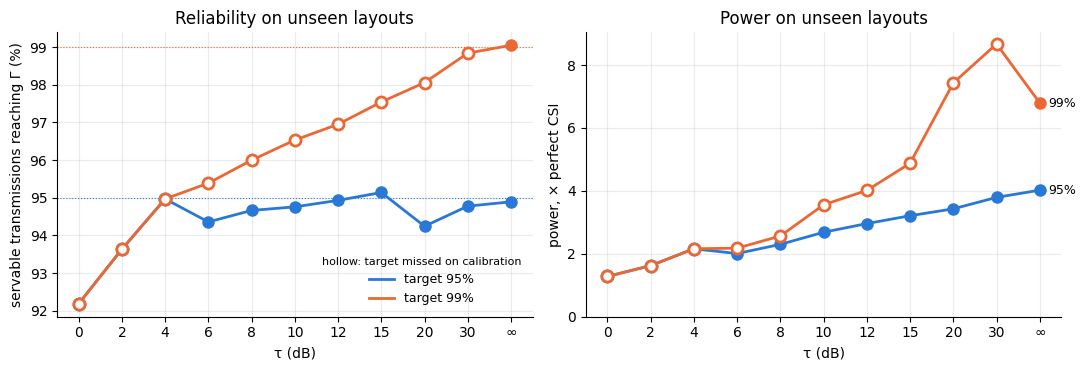

In [ ]:
colors = {0.95: '#2a78d6', 0.99: '#eb6834'}                            # categorical slots 1 and 2
x = np.arange(len(TAUS))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for target, color in colors.items():
    met = np.array([sweep[target, t]['met'] for t in TAUS])
    reached = np.array([100 * sweep[target, t]['reached'] for t in TAUS])
    power = np.array([sweep[target, t]['power'] for t in TAUS])
    for ax, y in ((ax1, reached), (ax2, power)):
        ax.plot(x, y, '-', color=color, lw=2, label=f'target {100 * target:.0f}%')
        ax.plot(x[met], y[met], 'o', color=color, ms=8)                        # filled: met on calibration
        ax.plot(x[~met], y[~met], 'o', ms=8, mfc='white', mec=color, mew=2)  # hollow: not met
    ax1.axhline(100 * target, color=color, lw=0.8, ls=':')
    ax2.annotate(f'{100 * target:.0f}%', (x[-1], power[-1]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9)
ax1.set(ylabel='servable transmissions reaching Γ (%)', xlabel='τ (dB)', title='Reliability on unseen layouts')
ax2.set(ylabel='power, × perfect CSI', xlabel='τ (dB)', title='Power on unseen layouts', ylim=(0, None))
for ax in (ax1, ax2):
    ax.set_xticks(x, [label(t) for t in TAUS])
    ax.grid(alpha=0.25)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
ax1.legend(frameon=False, loc='lower right', title='hollow: target missed on calibration', title_fontsize=8, fontsize=9)
plt.tight_layout()
plt.show()

The cheapest `(κ, τ)` per target on the calibration layouts, then the same pairs through the network on the unseen
layouts, to check the analysis:

In [ ]:
def tuned(target):
    "The (τ, sweep entry) reaching `target` on the calibration layouts with the least power there."
    ok = [tau for tau in TAUS if sweep[target, tau]['met']]
    tau = min(ok, key=lambda t: sweep[target, t]['cal_power'])
    return tau, sweep[target, tau]

checks = {}
for target in (0.95, 0.99):
    tau, s = tuned(target)
    control = lambda lay, table, m=s['margin']: LearnedChannelInversion(model, lay, table, lambda: headings, SNR_TARGET_DB, m, MAX_POWER_W)
    checks[target] = (tau, s, summary(*run(control, tau)))
print(f"{'':30s}{'reach Γ':>9s}{'power':>9s}{'withheld':>10s}{'garbled':>9s}")
for target, (tau, s, net) in checks.items():
    head = f"{100 * target:.0f}%: κ = {s['margin']:g} dB, τ = {label(tau)}"
    print(f"{head:30s}")
    for name, r in (('  analysis', s), ('  network', net)):
        print(f"{name:30s}{100 * r['reached']:8.1f}%{r['power']:8.2f}×{100 * r['withheld']:9.1f}%{100 * r['garbled']:8.1f}%")

                                reach Γ    power  withheld  garbled
95%: κ = 0.5 dB, τ = 6        
  analysis                        94.4%    2.01×      7.2%     6.8%
  network                         94.4%    2.01×      7.2%     6.5%
99%: κ = 7.75 dB, τ = ∞       
  analysis                        99.0%    6.79×      0.0%    72.0%
  network                         99.0%    6.79×      0.0%    72.4%


* **`δ` (`τ = 0`) is the cheapest rule, and caps the reliability.** With its own margin (0.5 dB), it reaches 92% of the
  servable transmissions at 1.3× perfect CSI's power, whatever the target. More margin only withholds more. (In the
  table above, `δ` had best effort's 7.75 dB margin, and reached 88%.) Up to `τ = 4` dB, neither target is reached on
  the calibration layouts, so both curves take the most reliable margin there, and coincide.
* **For 95%, a threshold of about 6 dB halves best effort's power.** `τ = 6` dB with a 0.5 dB margin, the cheapest pair
  on the calibration layouts, reaches 94.4% on the unseen ones at 2.0× perfect CSI's power. Best effort reaches 94.9%
  at 4.0×. It withholds 7.2% of the transmissions, mostly the links no power could serve (6.3%).
* **For 99%, best effort is the cheapest.** No finite `τ` reaches 99% on the calibration layouts: to lose only 1%,
  nothing can be withheld. Raising `τ` towards it costs more than best effort itself (8.7× at 30 dB), because the
  margin then has to make up for what the threshold still withholds.
* **The threshold also decides what arrives garbled.** Without a CRC, every unservable transmission that is sent goes
  out at `ρ_max` and mostly arrives wrong. The share of unservable messages arriving garbled grows with `τ`, from
  about 5–7% up to `τ = 6` dB to 72% with best effort. A CRC removes this, whatever `τ` is.

So `δ` is right if power matters more than reliability, and about 92% delivery is enough. A threshold of a few dB is the
cheapest way to a target around 95%, and best effort with a CRC is the way to 99%. Which one C3-WM should use depends
on how its world model copes with missing messages: that is its task success rate, which this example doesn't measure.

In [ ]:
assert out['perfect CSI (eq. 21)']['reached'] == 1.0 and abs(out['perfect CSI (eq. 21)']['power'] - 1) < 1e-9
assert out["C3-WM as written: Ψ, κ = 0, δ"]['reached'] < 0.5                        # the bias of a fit in |h|²
assert out['geometry + history, κ, best effort']['reached'] > 0.985                  # the margin transfers
assert out['geometry + history, κ, best effort']['reached'] > out["C3-WM's Ψ, κ, best effort"]['reached']
assert out['geometry + history, κ, δ']['withheld'] > 0.1 and out['geometry + history, κ, δ']['wrong'] < 0.01
for target, (tau, s, net) in checks.items():                                      # the analysis is the network
    assert abs(net['reached'] - s['reached']) < 0.005 and abs(net['power'] - s['power']) < 0.02 * s['power']
assert not sweep[0.99, 0.0]['met'] and sweep[0.99, math.inf]['met']               # δ can't reach 99%